In [1]:
import pandas as pd

df = pd.read_csv('../data/raw/lending_club_2020_train.csv')

/var/folders/7b/5yb3lly10933h9bwypfp3bgc0000gn/T/ipykernel_71240/3784752588.py:3: DtypeWarning: Columns (0: id) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/raw/lending_club_2020_train.csv')


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1755295 entries, 0 to 1755294
Columns: 141 entries, id to debt_settlement_flag
dtypes: float64(106), object(1), str(34)
memory usage: 2.2+ GB


In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

Path('../data/processed').mkdir(parents=True, exist_ok=True)

# 원본 캐시가 있으면 parquet에서, 없으면 CSV에서 읽어 저장
raw_pq = Path('../data/processed/lc_train.parquet')
if raw_pq.exists():
    df = pd.read_parquet(raw_pq)
else:
    df = pd.read_csv('../data/raw/lending_club_2020_train.csv', low_memory=False)
    df.to_parquet(raw_pq)

print(df.shape, f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

# 타깃과 시간 변수
df['target'] = df['loan_status'].isin(['Charged Off', 'Default']).astype('int8')
df['issue_q'] = pd.to_datetime(df['issue_d'], format='%b-%Y', errors='coerce').dt.to_period('Q')

# 1) 컬럼별 결측률
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print(f"결측 있는 컬럼: {len(miss)}개")
print(miss.to_string())

# 2) 결측 여부별 부실률 (결측이 타깃과 관련 있는지)
rows = []
for c in miss.index:
    isna = df[c].isna()
    rows.append((c, miss[c], df.loc[~isna, 'target'].mean(), df.loc[isna, 'target'].mean()))
res = pd.DataFrame(rows, columns=['col', 'miss_rate', 'default_if_observed', 'default_if_missing'])
res['gap'] = (res['default_if_missing'] - res['default_if_observed']).abs()
print(res.sort_values('gap', ascending=False).head(20).to_string(index=False))

# 3) 시기별 결측률 (특정 시점부터 생기는 컬럼 찾기)
by_q = df[miss.index].isna().groupby(df['issue_q']).mean()
print(by_q.iloc[:, :10].round(2).to_string())

# 4) 같이 비는 컬럼끼리 묶이는지
m = df[miss.index].isna().astype('int8')
corr = m.corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs[pairs > 0.95].sort_values(ascending=False).head(20))

(1755295, 141) 2.41 GB
결측 있는 컬럼: 141개
hardship_loan_status                          9.510578e-01
hardship_reason                               9.509877e-01
hardship_status                               9.509860e-01
hardship_dpd                                  9.509854e-01
hardship_start_date                           9.509849e-01
hardship_type                                 9.509849e-01
hardship_length                               9.509849e-01
deferral_term                                 9.509849e-01
payment_plan_start_date                       9.509849e-01
hardship_end_date                             9.509849e-01
orig_projected_additional_accrued_interest    9.387681e-01
hardship_last_payment_amount                  9.378275e-01
hardship_payoff_balance_amount                9.378275e-01
hardship_amount                               9.378275e-01
sec_app_revol_util                            9.334915e-01
verification_status_joint                     9.334112e-01
sec_app_chargeoff_

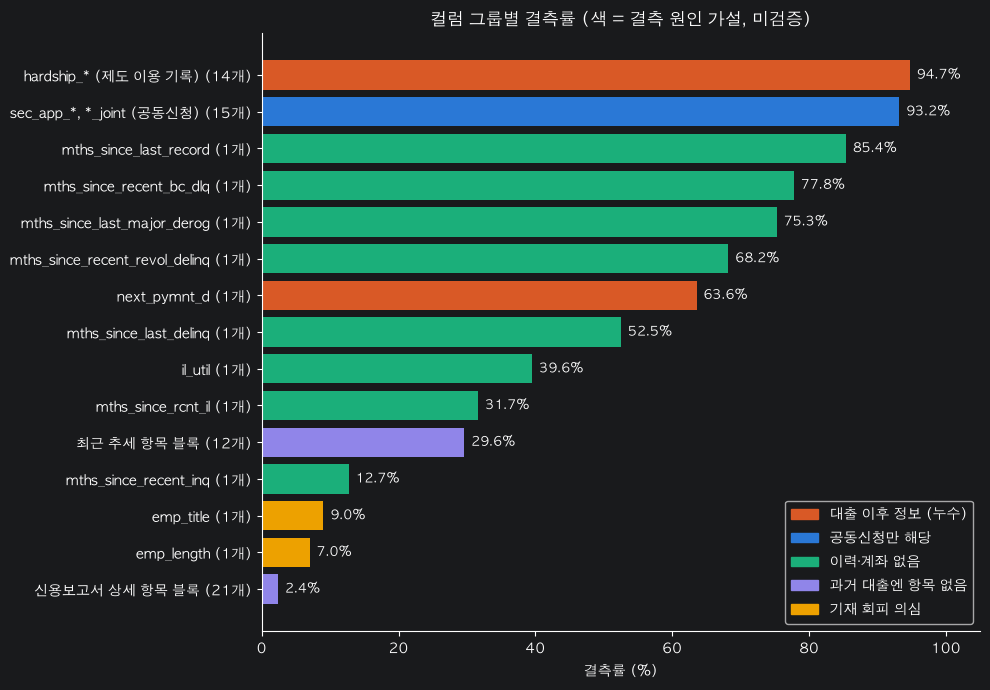

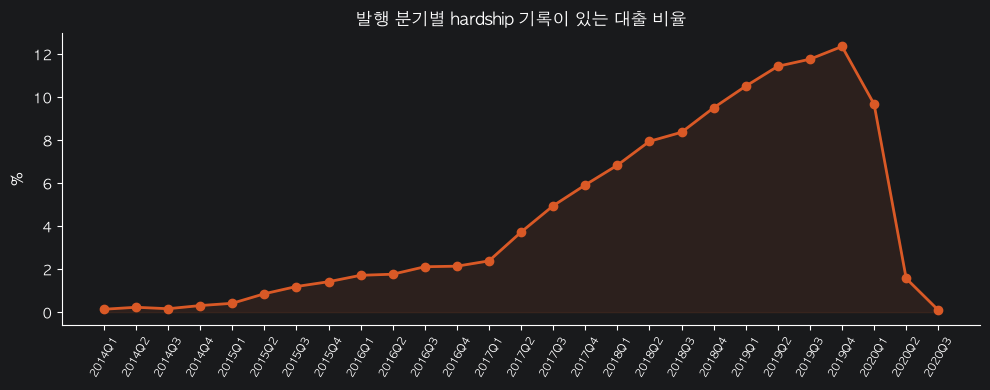

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_parquet('../data/processed/lc_train.parquet')
df = df[df['loan_status'].notna()]          # 빈 행 1개 제거
miss = df.isna().mean()

def band(lo, hi):
    return [c for c in miss.index if lo <= miss[c] < hi]

# 색 = 결측 원인 가설 (미검증)
LEAK, JOINT, NONE, NEWVAR, MNAR = '#d95926', '#2a78d6', '#1baf7a', '#9085e9', '#eda100'

hardship = [c for c in df.columns if c.startswith('hardship_') and c != 'hardship_flag'] \
           + ['deferral_term', 'payment_plan_start_date', 'orig_projected_additional_accrued_interest']
joint = [c for c in df.columns if c.startswith('sec_app_')] \
        + ['annual_inc_joint', 'dti_joint', 'revol_bal_joint', 'verification_status_joint']

groups = [
    ('hardship_* (제도 이용 기록)',    hardship, LEAK),
    ('next_pymnt_d',                  ['next_pymnt_d'], LEAK),
    ('sec_app_*, *_joint (공동신청)',  joint, JOINT),
    ('mths_since_last_record',        ['mths_since_last_record'], NONE),
    ('mths_since_recent_bc_dlq',      ['mths_since_recent_bc_dlq'], NONE),
    ('mths_since_last_major_derog',   ['mths_since_last_major_derog'], NONE),
    ('mths_since_recent_revol_delinq',['mths_since_recent_revol_delinq'], NONE),
    ('mths_since_last_delinq',        ['mths_since_last_delinq'], NONE),
    ('il_util',                       ['il_util'], NONE),
    ('mths_since_rcnt_il',            ['mths_since_rcnt_il'], NONE),
    ('mths_since_recent_inq',         ['mths_since_recent_inq'], NONE),
    ('최근 추세 항목 블록',             band(0.295, 0.297), NEWVAR),
    ('신용보고서 상세 항목 블록',        band(0.0235, 0.0245), NEWVAR),
    ('emp_title',                     ['emp_title'], MNAR),
    ('emp_length',                    ['emp_length'], MNAR),
]
rows = [(f"{name} ({len(cols)}개)", miss[cols].mean() * 100, color) for name, cols, color in groups]
rows.sort(key=lambda r: r[1])

# 그래프 1: 컬럼 그룹별 결측률
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh([r[0] for r in rows], [r[1] for r in rows], color=[r[2] for r in rows])
for i, r in enumerate(rows):
    ax.text(r[1] + 1, i, f"{r[1]:.1f}%", va='center', fontsize=9)
ax.set_xlim(0, 105)
ax.set_xlabel('결측률 (%)')
ax.set_title('컬럼 그룹별 결측률 (색 = 결측 원인 가설, 미검증)')
ax.legend(handles=[
    Patch(color=LEAK, label='대출 이후 정보 (누수)'),
    Patch(color=JOINT, label='공동신청만 해당'),
    Patch(color=NONE, label='이력·계좌 없음'),
    Patch(color=NEWVAR, label='과거 대출엔 항목 없음'),
    Patch(color=MNAR, label='기재 회피 의심'),
], loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('missing_by_group.png', dpi=150, bbox_inches='tight')
plt.show()

# 그래프 2: 발행 분기별 hardship 기록이 있는 대출 비율
d = df.copy()
d['issue_q'] = pd.to_datetime(d['issue_d'], format='%b-%Y').dt.to_period('Q')
share = d['hardship_reason'].notna().groupby(d['issue_q']).mean() * 100
share = share[share.index >= pd.Period('2014Q1')]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(share.index.astype(str), share.values, marker='o', color=LEAK, lw=2)
ax.fill_between(range(len(share)), share.values, alpha=0.1, color=LEAK)
ax.set_xticks(range(len(share)))
ax.set_xticklabels(share.index.astype(str), rotation=60, fontsize=8)
ax.set_ylabel('%')
ax.set_title('발행 분기별 hardship 기록이 있는 대출 비율')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('hardship_by_quarter.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
import numpy as np, pandas as pd, lightgbm as lgb
from sklearn.metrics import roc_auc_score, roc_curve

# ---------- 1) 데이터 준비: 종결 대출만 ----------
df = pd.read_parquet('../data/processed/lc_train.parquet')      # 원본 캐시 (누수 컬럼 포함)
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off', 'Default'])].copy()
df['target'] = df['loan_status'].isin(['Charged Off', 'Default']).astype('int8')
df['issue_year'] = pd.to_datetime(df['issue_d'], format='%b-%Y').dt.year

for c in ['earliest_cr_line', 'sec_app_earliest_cr_line']:      # 날짜 문자열은 연도 숫자로
    if c in df: df[c] = pd.to_datetime(df[c], format='%b-%Y', errors='coerce').dt.year.astype('float32')

LEAK_NUM = ['total_rec_prncp', 'total_pymnt', 'recoveries', 'last_pymnt_amnt', 'out_prncp']   # 누수 실험용
EXCLUDE = ['loan_status', 'target', 'issue_d', 'issue_year', 'issue_q', 'url', 'id', 'emp_title', 'title', 'zip_code',
           'policy_code', 'pymnt_plan', 'next_pymnt_d', 'last_pymnt_d', 'last_credit_pull_d',
           'last_fico_range_high', 'last_fico_range_low', 'debt_settlement_flag', 'total_pymnt_inv',
           'total_rec_int', 'total_rec_late_fee', 'collection_recovery_fee', 'out_prncp_inv'] + LEAK_NUM
EXCLUDE += [c for c in df.columns if c.startswith('hardship_') or c.startswith('settlement_')]
EXCLUDE += ['deferral_term', 'payment_plan_start_date', 'orig_projected_additional_accrued_interest']
clean = [c for c in df.columns if c not in EXCLUDE]

for c in clean:                                   # 숫자가 아니면 category (분할 전에 변환해 범주를 맞춤)
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].astype('category')

        # '13.56%' 처럼 숫자가 문자열로 들어온 컬럼을 숫자로 변환
for c in df.columns:
    if c in ('loan_status', 'issue_d') or pd.api.types.is_numeric_dtype(df[c]): continue
    s = df[c].astype('string').str.strip().str.rstrip('%')
    conv = pd.to_numeric(s, errors='coerce')
    n_ok = s.notna().sum()
    if n_ok > 0 and conv.notna().sum() >= 0.95 * n_ok:
        df[c] = conv.astype('float32'); print('숫자로 변환:', c)

# ---------- 2) 시간 순 분할 (연도는 vintage 곡선 보고 조정) ----------
tr, va, te = df[df.issue_year <= 2015], df[df.issue_year == 2016], df[df.issue_year == 2017]
print(len(tr), len(va), len(te), '부실률', tr.target.mean().round(3), va.target.mean().round(3), te.target.mean().round(3))

def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p); return (tpr - fpr).max()

def run(feats, name):
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=63, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.7, min_child_samples=100, n_jobs=-1, verbose=-1)
    m.fit(tr[feats], tr.target, eval_set=[(va[feats], va.target)], eval_metric='auc',
          callbacks=[lgb.early_stopping(100, verbose=False)])
    p = m.predict_proba(te[feats])[:, 1]
    print(f'{name:<22} AUC {roc_auc_score(te.target, p):.4f}  KS {ks(te.target, p):.4f}  트리 {m.best_iteration_}')
    return m

# ---------- 3) 비교 실험 ----------
print(f'LC 기준선(int_rate만)   AUC {roc_auc_score(te.target, te.int_rate):.4f}  KS {ks(te.target, te.int_rate):.4f}')
run(clean, '누수 제거 모델')
run(clean + LEAK_NUM, '누수 포함 모델(비교용)')

숫자로 변환: id
숫자로 변환: int_rate
숫자로 변환: revol_util
519789 242270 188207 부실률 0.181 0.196 0.211
LC 기준선(int_rate만)   AUC 0.6846  KS 0.2713


/opt/homebrew/Caskroom/miniconda/base/envs/cmapss/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


누수 제거 모델               AUC 0.7214  KS 0.3218  트리 510


/opt/homebrew/Caskroom/miniconda/base/envs/cmapss/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


누수 포함 모델(비교용)          AUC 0.9999  KS 0.9986  트리 116


,num_leaves,63
,learning_rate,0.03
,n_estimators,3000
,min_child_samples,100
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.7
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1


In [8]:
import warnings, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, lightgbm as lgb
from sklearn.metrics import roc_auc_score, roc_curve

# ===================== 설정 =====================
PATH = '../data/processed/lc_train.parquet'      # 원본 캐시(누수 컬럼 포함)
TRAIN_END, VALID_YEAR, TEST_YEAR = 2015, 2016, 2017   # 아래 vintage 표를 보고 조정
RUN_MISSING_EXPERIMENT = True                    # 결측 처리 비교(모델 2개 추가, 시간이 더 걸림)

# ===================== 1) 불러오기 =====================
t0 = time.time()
df = pd.read_parquet(PATH)
df = df[df['loan_status'].notna()].copy()                       # 빈 행 제거
df['issue_year'] = pd.to_datetime(df['issue_d'], format='%b-%Y').dt.year

# ===================== 2) vintage 표: 연도별 종결 비율과 부실률 =====================
df['resolved'] = df['loan_status'].isin(['Fully Paid', 'Charged Off', 'Default'])
df['bad'] = df['loan_status'].isin(['Charged Off', 'Default'])
df['is60'] = df['term'].astype('string').str.contains('60', na=False)
g = df.groupby('issue_year')
vint = pd.DataFrame({'전체': g.size(), '종결 비율': g['resolved'].mean().round(2)})
gr = df[df['resolved']].groupby('issue_year')
vint['종결 중 부실률'] = gr['bad'].mean().round(3)
vint['종결 중 60개월 비중'] = gr['is60'].mean().round(2)
print(vint.to_string()); vint.to_csv('vintage.csv')
safe = None
for y, r in vint['종결 비율'].items():
    if r >= 0.9: safe = y
    else: break
print(f'\n종결 비율 90% 이상이 유지되는 마지막 발행 연도: {safe}  (현재 설정: 테스트 {TEST_YEAR})\n', flush=True)

# ===================== 3) 종결 대출만 + 전처리 =====================
df = df[df['resolved']].copy()
df['target'] = df['bad'].astype('int8')

for c in ['earliest_cr_line', 'sec_app_earliest_cr_line']:      # 날짜 문자열 -> 연도
    if c in df: df[c] = pd.to_datetime(df[c], format='%b-%Y', errors='coerce').dt.year.astype('float32')

for c in df.columns:                                            # '13.56%' 같은 숫자 문자열 -> 숫자
    if c in ('loan_status', 'issue_d') or pd.api.types.is_numeric_dtype(df[c]) or df[c].dtype == bool: continue
    s = df[c].astype('string').str.strip().str.rstrip('%')
    conv = pd.to_numeric(s, errors='coerce'); n_ok = s.notna().sum()
    if n_ok > 0 and conv.notna().sum() >= 0.95 * n_ok:
        df[c] = conv.astype('float32'); print('숫자로 변환:', c)

LEAK_NUM = ['total_rec_prncp', 'total_pymnt', 'recoveries', 'last_pymnt_amnt', 'out_prncp']   # 누수 실험용
EXCLUDE = ['loan_status', 'target', 'resolved', 'bad', 'is60', 'issue_d', 'issue_year', 'issue_q', 'url', 'id',
           'emp_title', 'title', 'zip_code', 'policy_code', 'pymnt_plan', 'next_pymnt_d', 'last_pymnt_d',
           'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'debt_settlement_flag',
           'total_pymnt_inv', 'total_rec_int', 'total_rec_late_fee', 'collection_recovery_fee', 'out_prncp_inv',
           'deferral_term', 'payment_plan_start_date', 'orig_projected_additional_accrued_interest'] + LEAK_NUM
EXCLUDE += [c for c in df.columns if c.startswith('hardship_') or c.startswith('settlement_')]
clean = [c for c in df.columns if c not in EXCLUDE]

for c in clean:                                                 # 문자열은 category (분할 전에 변환)
    if not pd.api.types.is_numeric_dtype(df[c]) and df[c].dtype != bool:
        df[c] = df[c].astype('category')

tr = df[df.issue_year <= TRAIN_END]
va = df[df.issue_year == VALID_YEAR]
te = df[df.issue_year == TEST_YEAR]
print(f'특성 {len(clean)}개 | 학습 {len(tr):,} 검증 {len(va):,} 테스트 {len(te):,} | 부실률 '
      f'{tr.target.mean():.3f} / {va.target.mean():.3f} / {te.target.mean():.3f}', flush=True)

# ===================== 4) 실험 =====================
def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p); return (tpr - fpr).max()

results = []
def record(name, p, extra=''):
    auc, k = roc_auc_score(te.target, p), ks(te.target, p)
    results.append((name, round(auc, 4), round(k, 4)))
    print(f'{name:<24} AUC {auc:.4f}  KS {k:.4f} {extra}', flush=True)

def run(name, Xtr, Xva, Xte):
    t = time.time()
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=63, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.7, min_child_samples=100, n_jobs=-1, verbose=-1, importance_type='gain')
    m.fit(Xtr, tr.target, eval_set=[(Xva, va.target)], eval_metric='auc',
          callbacks=[lgb.early_stopping(100, verbose=False)])
    record(name, m.predict_proba(Xte)[:, 1], f'트리 {m.best_iteration_}  {time.time()-t:.0f}초')
    return m

record('LC 기준선(int_rate만)', te['int_rate'])

m_clean = run('누수 제거(NaN 그대로)', tr[clean], va[clean], te[clean])
imp = pd.Series(m_clean.feature_importances_, index=clean).sort_values(ascending=False)
print('\n중요도 상위 15 (gain 비율)'); print((imp / imp.sum()).head(15).round(3).to_string(), '\n', flush=True)

run('누수 포함(비교용)', tr[clean + LEAK_NUM], va[clean + LEAK_NUM], te[clean + LEAK_NUM])

if RUN_MISSING_EXPERIMENT:
    miss = tr[clean].isna().mean()
    flag_cols = list(miss[(miss > 0.01) & (miss < 0.99)].index)
    def with_flags(X):
        X2 = X[clean].copy()
        for c in flag_cols: X2[c + '_isna'] = X[c].isna().astype('int8')
        return X2
    run('누수 제거+결측 플래그', with_flags(tr), with_flags(va), with_flags(te))

    med = {c: tr[c].median() for c in clean if pd.api.types.is_numeric_dtype(tr[c]) and tr[c].dtype != bool}
    def imputed(X):
        X2 = X[clean].copy()
        for c in clean:
            if c in med: X2[c] = X2[c].fillna(med[c])
            elif isinstance(X2[c].dtype, pd.CategoricalDtype):
                if 'Unknown' not in X2[c].cat.categories: X2[c] = X2[c].cat.add_categories('Unknown')
                X2[c] = X2[c].fillna('Unknown')
        return X2
    run('누수 제거+중앙값 대치', imputed(tr), imputed(va), imputed(te))

print('\n===== 요약 ====='); res = pd.DataFrame(results, columns=['실험', 'AUC', 'KS'])
print(res.to_string(index=False)); res.to_csv('results_exp1.csv', index=False)
print(f'\n총 {(time.time()-t0)/60:.1f}분')

                전체  종결 비율  종결 중 부실률  종결 중 60개월 비중
issue_year                                       
2007           378   0.41     0.187           0.0
2008          1434   0.66     0.152           0.0
2009          3170   0.89     0.127           0.0
2010          7468   0.92     0.132          0.26
2011         12985   1.00     0.152          0.35
2012         32046   1.00     0.163          0.18
2013         81069   1.00     0.155          0.26
2014        140959   1.00     0.177          0.31
2015        252983   0.96     0.197           0.3
2016        261080   0.93     0.196           0.2
2017        265670   0.71     0.211          0.21
2018        297014   0.40     0.240          0.26
2019        311048   0.15     0.179          0.26
2020         87990   0.03     0.012          0.24

종결 비율 90% 이상이 유지되는 마지막 발행 연도: None  (현재 설정: 테스트 2017)

숫자로 변환: id
숫자로 변환: int_rate
숫자로 변환: revol_util
특성 101개 | 학습 519,789 검증 242,270 테스트 188,207 | 부실률 0.181 / 0.196 / 0.211
LC 기준선(int_rate만)        